In [1]:
# =============================================
# IMPORT
# =============================================
from utility.logger         import aiLogger
from keras.callbacks        import EarlyStopping, ReduceLROnPlateau
from model.componentModel   import mainModel
from model.tepSystemModel   import SystemModel
from preProcessingDataTEP   import PreProcessData
from prettytable            import PrettyTable

from keras.optimizers       import Adam
from utility.matpilotDraw   import MatPlot
from sklearn.preprocessing  import MinMaxScaler

import tensorflow           as tf
import pandas               as pd
import matplotlib.pyplot    as plt
import numpy                as np
import os, warnings
import random
import json


2025-09-23 18:14:16.052514: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2025-09-23 18:14:16.152025: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2025-09-23 18:14:16.152040: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.
2025-09-23 18:14:16.176822: E tensorflow/stream_executor/cuda/cuda_blas.cc:2981] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-09-23 18:14:16.855494: W tensorflow/stream_executor/platform/de

In [2]:
# ---------------------------
# Loading config file
# ---------------------------
with open('utility/modelConfig.json', 'r') as configFile:
    configData = json.load(configFile)
config = configData["tep"]  

# ---------------------------
# Set debug level and 
# ---------------------------
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '1'  # or any {'0', '1', '2'}
warnings.filterwarnings('ignore') 

os.environ["CUDA_VISIBLE_DEVICES"] = "0" 
np.random.seed(1)
random.seed(1)
tf.random.set_seed(1)

outputDir               = os.path.expanduser(config["dataDir"])
totalTraject            = 100
normalizeHI             = True
showRedundantShutdown   = False

#### Preprocessing data

In [3]:
# ==============================
# Config and data preprocessing
# ==============================
preData             = PreProcessData(config=config)
rawData             = preData.loadDataFromH5Format(dir              = outputDir, 
                                                   name             = "data/teps.h5",
                                                   case             = "all", 
                                                   reduceSampleRate = True, 
                                                   removeHigherThr  = False)

withRULData         = preData.addRULAndEnvironment(rawData)

norData             = preData.normalizeDataEachModes(rawData    = withRULData,
                                                     headline   =   preData.headline["allWithoutLabelNoBias"] + ["rul"])    # Normalize the data



Process:32571||2025-09-23 18:14:20,420-INFO [preProcessingDataTEP.py:loadDataFromH5Format():357]:Loading data from H5 files ...
Process:32571||2025-09-23 18:14:21,526-INFO [preProcessingDataTEP.py:loadDataFromH5Format():384]:Finish loading data from H5 files at case all...
Process:32571||2025-09-23 18:14:21,733-INFO [preProcessingDataTEP.py:addRULAndEnvironment():433]:Adding rul successfully...
Process:32571||2025-09-23 18:14:21,734-INFO [preProcessingDataTEP.py:normalizeDataEachModes():800]:Normalizing the data ...


casekey 1
Id                         100.000000
Time                       147.600000
environmentID                1.000000
D feed                     100.000000
E Feed                      10.555827
A Feed                      25.783258
A and C Feed                58.790394
Recycle                     71.166000
Purge                       70.586877
Separator                   33.468489
Stripper                    44.424011
Steam                        1.000000
Reactor Coolant             44.448015
Condenser Coolant          100.000000
Agitator                   100.000000
msv A Feed                   0.262918
msv D Feed                5881.025239
msv E Feed                 920.564119
msv A and C Feed             9.079431
Recycle Flow                24.691072
Reactor Feed Rate           37.184785
Reactor Pressure          2834.988166
Reactor Level              112.006829
Reactor Temperature        123.190089
Purge Rate                   0.646647
Product Sep Temp            90.810381
Pr

#### Declare the model

In [4]:
config["component"] = "Sys"
vaeSys = SystemModel(config = config)
vaeSys.build(input_shape=[(None, config["seqLength"], config["inReac"]), (None, 1, config["inReac"]), (None, 1)])
vaeSys.summary()


# modelDirComp1 = outputDir + "checkpoint/" + "bestModelReacNewData"
# modelDirComp2 = outputDir + "checkpoint/" + "bestModelSepNewData"
# modelDirComp3 = outputDir + "checkpoint/" + "bestModelStripNewData"
# modelDirSys   = outputDir + "checkpoint/" + "bestModelSysNewData"


modelDirComp1 = outputDir + "checkpoint/" + "bestModel34Reac"
modelDirComp2 = outputDir + "checkpoint/" + "bestModel35Sep"
modelDirComp3 = outputDir + "checkpoint/" + "bestModel36Strip"
modelDirSys   = outputDir + "checkpoint/" + "bestModel38Sys"
vaeSys.load_weights(modelDirComp1, modelDirComp2, modelDirComp3, modelDirSys)

2025-09-23 17:44:40.925346: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:980] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2025-09-23 17:44:40.926068: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2025-09-23 17:44:40.926223: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcublas.so.11'; dlerror: libcublas.so.11: cannot open shared object file: No such file or directory
2025-09-23 17:44:40.926322: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcublasLt.so.11'; dlerror: libcublasLt.so.11: cannot open shared object file: No such file or directory
2025-09-23 17:44:40.926691: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Co

The shape of sysHILayer (None, 8, 5)
The shape of sysHILayer (None, 8, 5)
The shape of sysHILayer (None, 8, 5)
The shape of sysHILayer (None, 8, 5)
The shape of sysHILayer (None, 8, 5)
The shape of sysHILayer (None, 8, 5)


Process:25682||2025-09-23 17:44:41,883-INFO [tepSystemModel.py:loadWeightAndFreezePretrainedHI():923]:Loading the model at the direction: /home/ducan/Desktop/Dropbox/1.codeData/tepDataWithoutGit/checkpoint/bestModel34Reac, /home/ducan/Desktop/Dropbox/1.codeData/tepDataWithoutGit/checkpoint/bestModel35Sep, /home/ducan/Desktop/Dropbox/1.codeData/tepDataWithoutGit/checkpoint/bestModel36Strip
Process:25682||2025-09-23 17:44:41,919-INFO [tepSystemModel.py:loadWeightAndFreezePretrainedHI():962]:Loaded the model at the direction:('/home/ducan/Desktop/Dropbox/1.codeData/tepDataWithoutGit/checkpoint/bestModel34Reac', '/home/ducan/Desktop/Dropbox/1.codeData/tepDataWithoutGit/checkpoint/bestModel35Sep', '/home/ducan/Desktop/Dropbox/1.codeData/tepDataWithoutGit/checkpoint/bestModel36Strip') and freezed it successfully!!!
Process:25682||2025-09-23 17:44:41,936-DEBUG [tepSystemModel.py:__init__():313]:The shape of hiSelectionInput (None, 120)
Process:25682||2025-09-23 17:44:41,965-DEBUG [tepSystemMo

Model: "system_model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 sensor_selection (SensorSel  multiple                 135       
 ection)                                                         
                                                                 
 sensor_selection_1 (SensorS  multiple                 135       
 election)                                                       
                                                                 
 sensor_selection_2 (SensorS  multiple                 135       
 election)                                                       
                                                                 
 encoder (Functional)        [(None, 1),               103906    
                              (None, 8, 5)]                      
                                                                 
 decoder (Functional)        (None, 128, 45)          

Process:25682||2025-09-23 17:44:43,306-INFO [tepSystemModel.py:load_weights():888]:Loading the model at the direction: /home/ducan/Desktop/Dropbox/1.codeData/tepDataWithoutGit/checkpoint/bestModel34Reac, /home/ducan/Desktop/Dropbox/1.codeData/tepDataWithoutGit/checkpoint/bestModel35Sep, /home/ducan/Desktop/Dropbox/1.codeData/tepDataWithoutGit/checkpoint/bestModel36Strip, /home/ducan/Desktop/Dropbox/1.codeData/tepDataWithoutGit/checkpoint/bestModel38Sys
Process:25682||2025-09-23 17:44:43,339-INFO [tepSystemModel.py:load_weights():920]:Loaded the model at the direction:/home/ducan/Desktop/Dropbox/1.codeData/tepDataWithoutGit/checkpoint/bestModel34Reac, /home/ducan/Desktop/Dropbox/1.codeData/tepDataWithoutGit/checkpoint/bestModel35Sep, /home/ducan/Desktop/Dropbox/1.codeData/tepDataWithoutGit/checkpoint/bestModel36Strip, /home/ducan/Desktop/Dropbox/1.codeData/tepDataWithoutGit/checkpoint/bestModel38Sys successfully!!!


### MAKS EACH COMPONENT IN EACH ENVIRONMENT

#### Reactor

In [5]:
binaryMaskReac, probsReac     = vaeSys.maskCr1.getMask()
for idxEnv in range(3):
    ssTable                 = PrettyTable()
    ssTable.field_names     = ["No","sensorName","probability", "binary"]
    print(f"The number of selected sensor in the environment {idxEnv+1} is {sum(binaryMaskReac[idxEnv])}")
    for idx,idxSS in enumerate(preData.headline["allWithoutLabelNoBias"]):
        ssTable.add_row([idx,idxSS,probsReac[idxEnv][idx].numpy(),binaryMaskReac[idxEnv][idx].numpy()])

    print(ssTable)

The number of selected sensor in the environment 1 is 26.0
+----+------------------------+---------------+--------+
| No |       sensorName       |  probability  | binary |
+----+------------------------+---------------+--------+
| 0  |         E Feed         |   0.9999999   |  1.0   |
| 1  |         A Feed         | 1.0593292e-12 |  0.0   |
| 2  |      A and C Feed      |   0.9999999   |  1.0   |
| 3  |         Purge          |      1.0      |  1.0   |
| 4  |       Separator        |      1.0      |  1.0   |
| 5  |        Stripper        |   0.9999999   |  1.0   |
| 6  |    Reactor Coolant     | 1.0623663e-12 |  0.0   |
| 7  |   Condenser Coolant    | 1.0650789e-12 |  0.0   |
| 8  |       msv A Feed       | 1.0599759e-12 |  0.0   |
| 9  |       msv D Feed       |      1.0      |  1.0   |
| 10 |       msv E Feed       |   0.9999999   |  1.0   |
| 11 |    msv A and C Feed    |   0.9999999   |  1.0   |
| 12 |      Recycle Flow      |      1.0      |  1.0   |
| 13 |   Reactor Feed Rate   

#### Separator

In [6]:
binaryMaskReac, probsReac     = vaeSys.maskCr2.getMask()
for idxEnv in range(3):
    ssTable                 = PrettyTable()
    ssTable.field_names     = ["No","sensorName","probability", "binary"]
    print(f"The number of selected sensor in the environment {idxEnv+1} is {sum(binaryMaskReac[idxEnv])}")
    for idx,idxSS in enumerate(preData.headline["allWithoutLabelNoBias"]):
        ssTable.add_row([idx,idxSS,probsReac[idxEnv][idx].numpy(),binaryMaskReac[idxEnv][idx].numpy()])

    print(ssTable)



The number of selected sensor in the environment 1 is 13.0
+----+------------------------+---------------+--------+
| No |       sensorName       |  probability  | binary |
+----+------------------------+---------------+--------+
| 0  |         E Feed         | 4.6886475e-13 |  0.0   |
| 1  |         A Feed         | 4.6633183e-13 |  0.0   |
| 2  |      A and C Feed      | 4.6340227e-13 |  0.0   |
| 3  |         Purge          | 4.6123657e-13 |  0.0   |
| 4  |       Separator        |  4.627496e-13 |  0.0   |
| 5  |        Stripper        |      1.0      |  1.0   |
| 6  |    Reactor Coolant     |   4.5894e-13  |  0.0   |
| 7  |   Condenser Coolant    |      1.0      |  1.0   |
| 8  |       msv A Feed       | 4.6479915e-13 |  0.0   |
| 9  |       msv D Feed       |      1.0      |  1.0   |
| 10 |       msv E Feed       | 4.6254927e-13 |  0.0   |
| 11 |    msv A and C Feed    | 4.5658963e-13 |  0.0   |
| 12 |      Recycle Flow      |      1.0      |  1.0   |
| 13 |   Reactor Feed Rate   

#### Stripper

In [7]:
binaryMaskReac, probsReac     = vaeSys.maskCv2.getMask()
for idxEnv in range(3):
    ssTable                 = PrettyTable()
    ssTable.field_names     = ["No","sensorName","probability", "binary"]
    print(f"The number of selected sensor in the environment {idxEnv+1} is {sum(binaryMaskReac[idxEnv])}")
    for idx,idxSS in enumerate(preData.headline["allWithoutLabelNoBias"]):
        ssTable.add_row([idx,idxSS,probsReac[idxEnv][idx].numpy(),binaryMaskReac[idxEnv][idx].numpy()])

    print(ssTable)

The number of selected sensor in the environment 1 is 19.0
+----+------------------------+---------------+--------+
| No |       sensorName       |  probability  | binary |
+----+------------------------+---------------+--------+
| 0  |         E Feed         | 1.7232654e-13 |  0.0   |
| 1  |         A Feed         | 1.6705837e-13 |  0.0   |
| 2  |      A and C Feed      | 1.9034904e-13 |  0.0   |
| 3  |         Purge          |   0.9999999   |  1.0   |
| 4  |       Separator        |      1.0      |  1.0   |
| 5  |        Stripper        | 1.9865824e-13 |  0.0   |
| 6  |    Reactor Coolant     | 1.6826333e-13 |  0.0   |
| 7  |   Condenser Coolant    |      1.0      |  1.0   |
| 8  |       msv A Feed       | 1.6601523e-13 |  0.0   |
| 9  |       msv D Feed       |   0.9999999   |  1.0   |
| 10 |       msv E Feed       | 1.6638454e-13 |  0.0   |
| 11 |    msv A and C Feed    | 1.7078404e-13 |  0.0   |
| 12 |      Recycle Flow      | 1.5469925e-13 |  0.0   |
| 13 |   Reactor Feed Rate   

### HI FOR EACH ENVIRONMENT

In [8]:
# Plot functions
import plotly.graph_objects as go
import os
def draw2DMultipleY(
                    xCoor       = [0,10],
                    yCoor       = [[0,10],[10,1]],
                    yLabel      = "Y Value",
                    xLabel      = "Time Unit",
                    title       = "XYAxis",
                    saveFig     = False,
                    direction   = "checkpoint/",
                    savedName   = "default",
                    useLegend   = True,
                    legend      = ["line1","line2"],
                    color       = ["blue","green"],
                    yLim       = [],):
    
    plt.figure()
    for idx,yValue in enumerate(yCoor):
        plt.plot(xCoor,yValue, color=color[idx])

    plt.title(title)
    # plt.xlabel(xLabel)
    # plt.ylabel(yLabel)

    if len(yLim) != 0:
        plt.ylim(yLim)
    if useLegend:
        plt.legend(legend, loc='upper left')
    plt.grid(True)
    if saveFig:
        
        if not os.path.exists(direction):
            os.makedirs(direction)
        plt.savefig(direction + savedName + '.png')
        plt.close()
    else:
        plt.show()


def draw2DMultipleY_plotly(
        xCoor=[0, 10],
        yCoor=[[0, 10], [10, 1]],
        yLabel="Y Value",
        xLabel="Time Unit",
        title="XYAxis",
        saveFig=False,
        direction="checkpoint/",
        savedName="default",
        useLegend=True,
        legend=["line1", "line2"],
        color=["blue", "green"],
        yLim=[]
    ):

    fig = go.Figure()

    for idx, yValue in enumerate(yCoor):
        fig.add_trace(go.Scatter(
            x=xCoor,
            y=yValue,
            mode='lines',
            name=legend[idx] if useLegend else None,
            line=dict(color=color[idx])
        ))

    # fig.update_layout(
    #     title=title,
    #     xaxis_title=xLabel,
    #     yaxis_title=yLabel,
    #     yaxis=dict(range=yLim if yLim else None),
    #     showlegend=useLegend
    # )
    fig.update_layout(
    title=title,
    xaxis_title=xLabel,
    yaxis_title=yLabel,
    yaxis=dict(range=yLim if yLim else None),
    showlegend=useLegend,
    plot_bgcolor='white',
    paper_bgcolor='white'
)


    if saveFig:
        if not os.path.exists(direction):
            os.makedirs(direction)
        fig.write_image(f"{direction}{savedName}.png")
    else:
        fig.show()


#### Environment 4

In [9]:
dfHIAll = pd.DataFrame(columns=[
                                'oriReacHI',
                                'oriSepHI',
                                'oriStripHI',
                                'oriSysHI',
                                'time'
                            ])

environmentIdx      = 4
data                = norData[environmentIdx]
trajectID           = data["Id"]
reactor             = data[preData.headline["reactor"]]
separator           = data[preData.headline["separator"]]
stripper            = data[preData.headline["stripper"]]
allSensor           = data[preData.headline["allWithoutLabelNoBias"]]
rul                 = data["rul"]
env                 = data["environmentID"]
timeTraj            = data["Time"]

hiEnv1              = {}
rulEnv1             = {}
hiEnv1["Reac"]      = []
rulEnv1["Reac"]     = []
hiEnv1["Sep"]       = []
rulEnv1["Sep"]      = []
hiEnv1["Strip"]     = []
rulEnv1["Strip"]    = []
hiEnv1["Sys"]       = []
rulEnv1["Sys"]     = []
hiEnv1["multipliedMatrix"]       = []
timeDraw            = []
hiEnv1["timeDraw"] = []

# timeEachCase        = withoutInitRawData[environmentIdx].groupby('Id',sort=False)['Time']
# trajecTime          = [eachTrajectTime[1] for eachTrajectTime in timeEachCase]                  #Extract time from the tuple and groupby
# for eachTrajectTime in timeEachCase:
#     print(len(eachTrajectTime)) 

for idx in range(totalTraject):
    getAtIdx = idx + 1
    print(f"Getting the HI at the idx {getAtIdx}")
    # seqXTrainEnv, seqXAllSensorTrain,seqTime     = preData.getTensorData(   dataList    = [env,allSensor,timeTraj],
    #                                                                         trajectId   = trajectID,
    #                                                                         getAtIdx    = getAtIdx,   
    #                                                                         seqLength   = config["seqLength"],
    #                                                                         overlap     = config["overLap"]
    #                                                                     )
    seqXAllSensorTrain,     \
    seqXRulTrain,           \
    seqXTrainEnv,seqTime                = preData.getTensorData(dataList    = [allSensor,rul,env,timeTraj],
                                                                trajectId   = trajectID,  
                                                                shuffle     = False,      
                                                                getAtIdx    = getAtIdx,
                                                                seqLength   = preData.config["seqLength"],
                                                                overlap     = preData.config["overLap"]         
                                                                )
    seqTimeTrain        = seqTime[:,-1,:]

    xPredict            = [seqXAllSensorTrain, seqTime[:,-1,:], seqXTrainEnv[:,-1,:]]  

    hiReac, hiSep,  hiStrip, hiSystem, predictedRul, hiMatrixOutput    = vaeSys.getHIandRUL(input = xPredict)
    # squeezedHiSystem                    = tf.reduce_mean(hiSystem,axis=-1)
    # print(squeezedHiSystem.shape)
    squeezedHiReac                                 = tf.squeeze(hiReac, axis=-1)
    squeezedHiSep                                  = tf.squeeze(hiSep, axis=-1)
    squeezedHiStrip                                = tf.squeeze(hiStrip, axis=-1)
    squeezedHiSys                                  = tf.squeeze(hiSystem, axis=-1)
    timeDraw.append(seqTimeTrain)


    dfTemp      = pd.DataFrame({'id'           : np.ones(squeezedHiReac.shape)*idx,
                                'oriReacHI'    : squeezedHiReac.numpy(), 
                                'oriSepHI'     : squeezedHiSep.numpy(),
                                'oriStripHI'   : squeezedHiStrip.numpy(),
                                'oriSysHI'     : squeezedHiSys.numpy(),
                                'time'      : np.squeeze(seqTimeTrain)})
    

    dfHIAll     = pd.concat([dfHIAll,dfTemp],ignore_index=True)

dfHIAll["reacHI"]   = dfHIAll["oriReacHI"].copy()
dfHIAll["sepHI"]    = dfHIAll["oriSepHI"].copy()
dfHIAll["stripHI"]  = dfHIAll["oriStripHI"].copy()



    # hiEnv1["Reac"].append(hiReac)
    # hiEnv1["Sep"].append(hiSep)
    # hiEnv1["Strip"].append(hiStrip)
    # hiEnv1["Sys"].append(hiSystem)
    # hiEnv1["timeDraw"].append(seqTimeTrain)
    # hiEnv1["multipliedMatrix"].append(hiMatrixOutput)
    # rulEnv1["Sys"].append(predictedRul)
    # rulEnv1["Reac"].append(squeezedRulReac)
    # rulEnv1["Sep"].append(squeezedRulSep)
    # rulEnv1["Strip"].append(squeezedRulStrip)

    # break
    


# if normalizeHI:
#     [hiEnv1["Reac"], hiEnv1["Sep"], hiEnv1["Strip"],hiEnv1["Sys"]], timeDraw , rulEnv1["Sys"], hiEnv1["multipliedMatrix"]= preData.normalizeHIInGeneral(inData = [hiEnv1["Reac"], hiEnv1["Sep"], hiEnv1["Strip"],hiEnv1["Sys"]], time= timeDraw, rul = rulEnv1["Sys"], multipliedMt = hiEnv1["multipliedMatrix"], indexToShutdown = 2, showRedundantShutdown = showRedundantShutdown)
# hiEnv1["Sys"]                                  = preData.normalizeHIInGeneral(inData = [hiEnv1["Reac"], hiEnv1["Sep"], hiEnv1["Strip"]], indexToShutdown = 2)


Process:25682||2025-09-23 17:44:43,876-INFO [preProcessingDataTEP.py:getTensorData():861]:Spliting data into sequences now ...


Getting the HI at the idx 1


Process:25682||2025-09-23 17:44:44,727-INFO [preProcessingDataTEP.py:getTensorData():861]:Spliting data into sequences now ...


Getting the HI at the idx 2


Process:25682||2025-09-23 17:44:45,204-INFO [preProcessingDataTEP.py:getTensorData():861]:Spliting data into sequences now ...


Getting the HI at the idx 3


... (190 outputs left out)

Process:25682||2025-09-23 17:45:36,738-INFO [preProcessingDataTEP.py:getTensorData():861]:Spliting data into sequences now ...


Getting the HI at the idx 99


Process:25682||2025-09-23 17:45:37,385-INFO [preProcessingDataTEP.py:getTensorData():861]:Spliting data into sequences now ...


Getting the HI at the idx 100


In [10]:
print(dfHIAll)

        oriReacHI    oriSepHI   oriStripHI     oriSysHI    time    id  \
0       -0.372543   -0.122561    -0.107974    -0.372543   12.70   0.0   
1       -0.576855   -0.091317    -0.107974    -0.576855   12.80   0.0   
2       -0.381688   -0.045886    -0.107974    -0.381688   12.90   0.0   
3       -0.391851   -0.212380    -0.107974    -0.391851   13.00   0.0   
4       -0.518589   -0.131210    -0.107974    -0.518589   13.10   0.0   
...           ...         ...          ...          ...     ...   ...   
110103 -70.567055 -170.644501 -1031.333252 -1031.333130  125.05  99.0   
110104 -70.980583 -169.367752  -994.049377  -994.049316  125.15  99.0   
110105 -71.102341 -171.559921 -1012.563293 -1012.563232  125.25  99.0   
110106 -71.270737 -173.516876 -1020.530273 -1020.530212  125.35  99.0   
110107 -71.857391 -171.310104 -1063.896240 -1063.896118  125.45  99.0   

           reacHI       sepHI      stripHI  
0       -0.372543   -0.122561    -0.107974  
1       -0.576855   -0.091317    

#### Normalize for specific sample

(110108, 3)
     oriReacHI  oriSepHI  oriStripHI  oriSysHI  time   id    reacHI     sepHI  \
273  -1.384613 -0.020492   -0.107974 -1.384613   0.0  0.0  0.999900  0.999782   
274  -1.555112 -0.078207   -0.107974 -1.555111   0.1  0.0  0.999859  0.999778   
275  -1.536813 -0.140432   -0.107974 -1.536813   0.2  0.0  0.999808  0.999775   
276  -1.559905 -0.079383   -0.107974 -1.559905   0.3  0.0  0.999749  0.999784   
277  -1.328751 -0.163257   -0.107974 -1.328751   0.4  0.0  0.999697  0.999789   

      stripHI     sysHI  
273  0.999724  0.999724  
274  0.999724  0.999724  
275  0.999724  0.999724  
276  0.999724  0.999724  
277  0.999724  0.999697  
1422     0.0
1423     0.1
1424     0.2
1425     0.3
1426     0.4
        ... 
2193    77.1
2194    77.2
2195    77.3
2196    77.4
2197    77.5
Name: time, Length: 776, dtype: float64


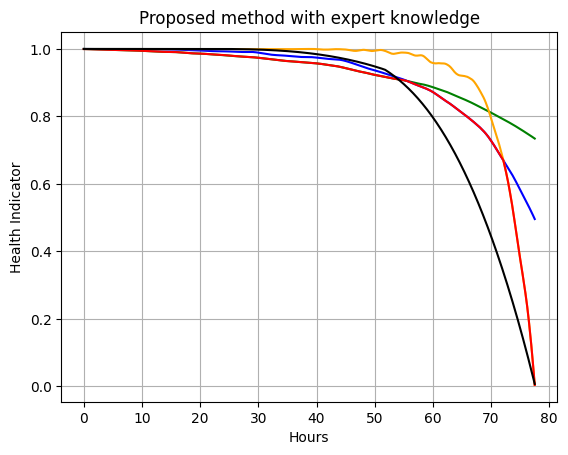

In [11]:
drawId = 1

hiColumns = ["reacHI", "sepHI", "stripHI"]

# ===================================
# Moving average for HIs
# -----------------------------------
print(dfHIAll[hiColumns].shape)
for _ in range(2):
    for col in hiColumns:
        dfHIAll[col] = (dfHIAll[col].transform(lambda x: x.rolling(window=15, min_periods=1).mean()))

dfHIAll             = dfHIAll[dfHIAll["time"] >= 40]               # 
dfHIAll["time"]     = dfHIAll["time"] - dfHIAll["time"].min()     # Normalize time to start from 0

# ====================================
# Normalize for HIs
# ------------------------------------
globalMax           = dfHIAll.groupby('id')[hiColumns].max().max(axis = 1).reset_index(name='globalMax')   # Get the global maximum for each ids
maxPerIdEachCol     = dfHIAll.groupby('id')[hiColumns].max().reset_index()                                 # Get the maximum value for each column across all ids

shiftMatrix         = pd.DataFrame({    'reacHI': globalMax['globalMax'] -  maxPerIdEachCol['reacHI'],
                                        'sepHI':  globalMax['globalMax'] -  maxPerIdEachCol['sepHI'],
                                        'stripHI': globalMax['globalMax'] - maxPerIdEachCol['stripHI'],
                                    })                                                                             # Create a shift matrix to adjust the HI values


dfHIAll[hiColumns]  =  dfHIAll.groupby('id')[hiColumns].apply(lambda group: group + shiftMatrix.loc[group.name,:])  # Adjust the HI values by adding the shift matrix


upperHIs            = max(globalMax['globalMax'])                                                           # Use the global maximum for normalization
hiThreshold         = max(dfHIAll.groupby('id')['stripHI'].min())


dfHIAll             = dfHIAll[dfHIAll['stripHI'] > hiThreshold]                                             # Filter out engines with HI > threshold

dfHIAll[hiColumns]  = (dfHIAll[hiColumns] - hiThreshold) / (upperHIs - hiThreshold)           # Normalize HI


dfHIAll["sysHI"]    = dfHIAll[hiColumns].min(axis=1)  
print(dfHIAll.head(5))

dfHIAll.to_excel("allHIs.xlsx", index=False)


label = pd.read_excel("~/Desktop/Dropbox/1.codeData/tepDataWithoutGit/data/labelToDraw.xlsx")
stripper_max_abs = label["Stripper"].abs().max()
data_normalized = label.copy()
data_normalized["Stripper"] = 1 + label["Stripper"] / stripper_max_abs
data_normalized["Separator"] = 1 + label["Separator"] / stripper_max_abs
data_normalized["Reactor"] = 1 + label["Reactor"] / stripper_max_abs

systemLabel     = data_normalized[["Stripper", "Separator", "Reactor"]].min(axis=1)
systemLabel     = systemLabel.iloc[1:-1]

plot2 = MatPlot()
drawData = dfHIAll[dfHIAll["id"] == 1]  # Filter for a specific engine ID, e.g., 1
print(drawData["time"])

plot2.draw2DMultipleY(xCoor =   drawData["time"], 
                      yCoor =   [drawData["reacHI"], drawData["sepHI"], drawData["stripHI"], drawData["sysHI"], systemLabel],
                      color = ["green","blue","orange","red", 'black'],
                      useLegend= False,
                      title = "Proposed method with expert knowledge",
                      xLabel = "Hours",
                      yLabel= "Health Indicator",)



In [12]:
def subPlotMultiImgPandas(
                        inData      = None,
                        inYLabel    = ["reacHI","sepHI", "stripHI", "sysHI"],
                        subPlotName = "Name",
                        numRow      = 2,
                        numCol      = 2,
                        color       = None,
                        xLim        = [],
                        yLim        = []
                        ):
        inX         = inData["time"]
        idxTraject  = inData["id"]
        his         = inData[inYLabel]

        # print(idxTraject.unique())
        # print(max(idxTraject))
        # ------------------------
        # The size of figure to 
        # display
        # ------------------------
        subplotWidth    = 4  # inches
        subplotHeight   = 4  # inches

        figWidth    = numCol * subplotWidth
        figHeight   = numRow * subplotHeight

        # ------------------------
        # Create subplot
        # ------------------------
        fig, axes = plt.subplots(numRow, numCol, figsize=(figWidth,figHeight), sharey=False)
        # print("=====================", axes)
        axes = axes.flatten()

        for idxEachHi in range(len(idxTraject.unique())):            # Run for each hi element inside each component
            for idxComp in range(len(inYLabel)):             # Run for each component
            
                axes[idxEachHi].plot(inX[idxTraject == idxEachHi], his[idxTraject == idxEachHi][inYLabel[idxComp]],color=color[idxComp])

            axes[idxEachHi].set_title("T" + str(idxEachHi+1))
            axes[idxEachHi].grid(True)  # Add grid
            if (len(yLim) != 0):
                axes[idxEachHi].set_ylim(yLim) 
        plt.tight_layout()
        plt.show()

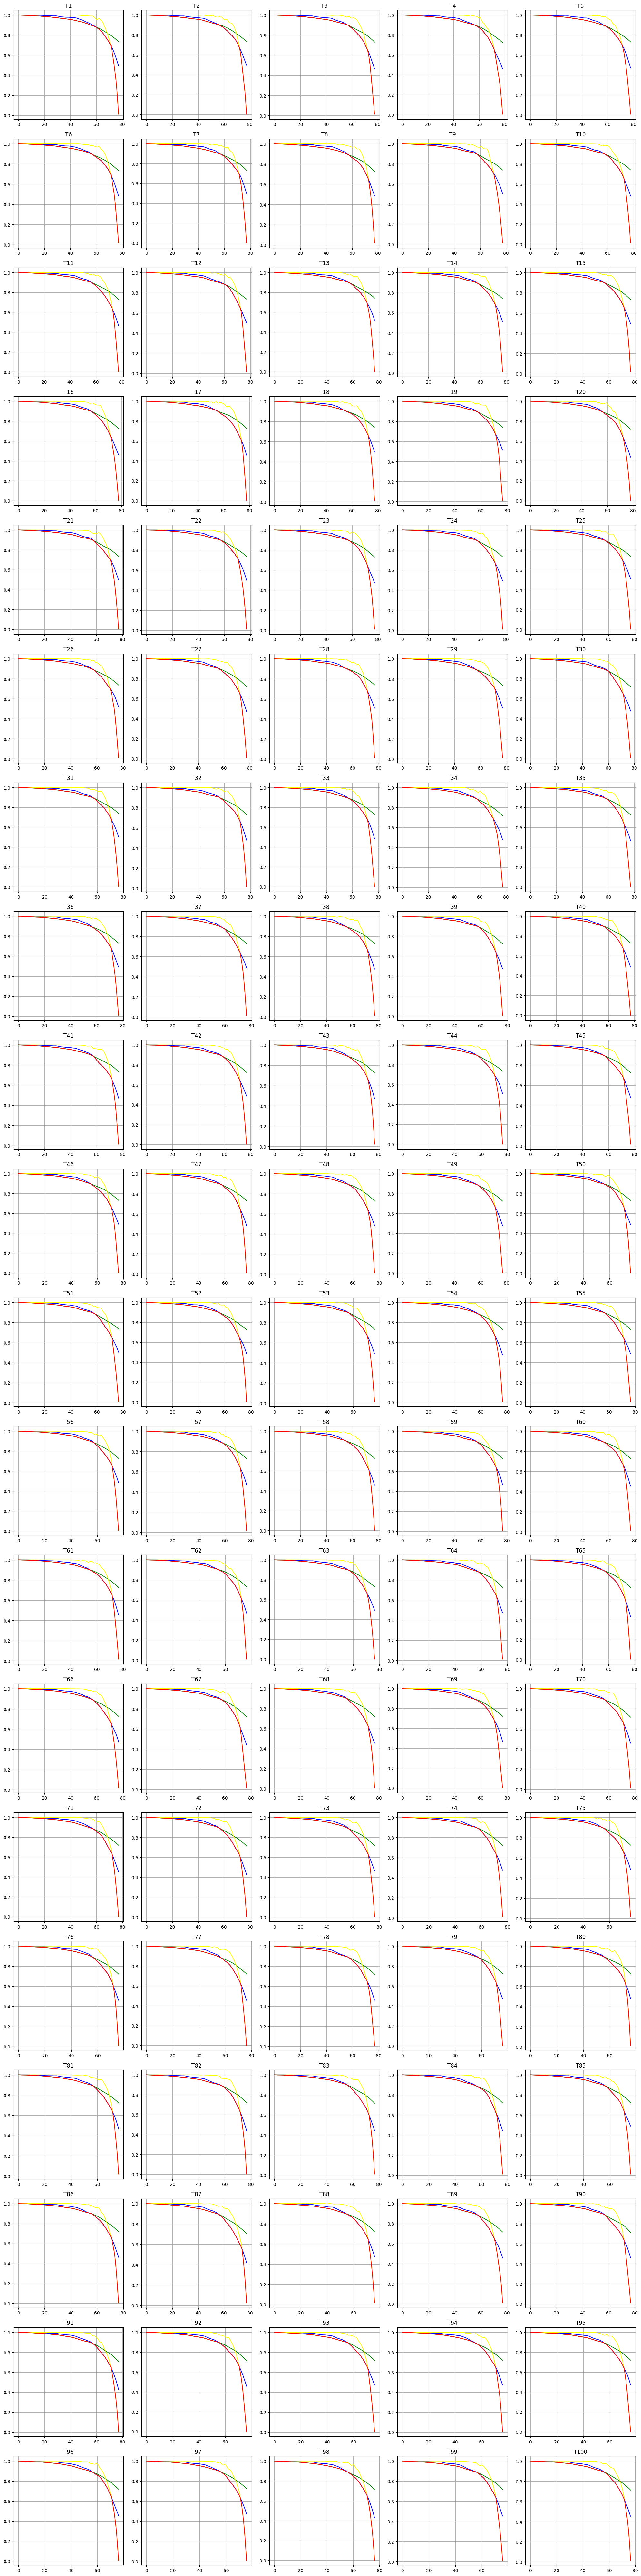

In [13]:
subPlotMultiImgPandas(inData=dfHIAll,numRow=20, numCol=5,color=['green','blue', 'yellow','red'])

In [14]:
# plot5 = MatPlot() 
# plot5.subPlotMultiImg(inY = [hiEnv1["Reac"], hiEnv1["Sep"], hiEnv1["Strip"], hiEnv1["Sys"]], inX= timeDraw, color=['green','blue', 'yellow','red'], numRow=20, numCol=5)

In [15]:
# plot6 = MatPlot( )
# plot6.subPlotMultiImg(inY = [rulEnv1["Sys"]], inX=timeDraw, color=['g'], numRow=20, numCol=5)

In [16]:
# lookup = {0: -1, 1: 1, 2: 0}
# showMatrix = []
# for idxMulMatrix in hiEnv1["multipliedMatrix"]:
#     signal = [lookup[np.argmax(row)] for row in idxMulMatrix]
#     showMatrix.append(signal)

# plot2 = MatPlot()
# plot2.subPlotMultiImg(inY = [showMatrix], inX=timeDraw, color=['g'], numRow=20, numCol=5, yLim= [-2,2])